# Fallen Angels: The Best of High Yield or The Worst of Investment Grade

This notebook examines the return characteristics of Fallen Angel bonds and their relationship with other fixed income sectors. In particular, it investigates whether Fallen Angels behave more like investment-grade bonds or high-yield bonds.

From a theoretical perspective, Fallen Angels are expected to exhibit characteristics closer to high-yield bonds, as credit markets are likely to anticipate the deterioration in credit quality before a formal downgrade occurs. However, the investment thesis behind Fallen Angel strategies is not simply to gain exposure to credit risk. Rather, the objective is to harvest the price dislocations created by forced selling from investment-grade investors following a downgrade, while assuming as little incremental credit risk as possible.

# Packages

In [47]:
import os
import sys
import numpy as np
import pandas as pd
import datetime as dt
import statsmodels.api as sm

import matplotlib.pyplot as plt
from   matplotlib.lines import Line2D
from   matplotlib.ticker import FuncFormatter

In [48]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
data_path = os.path.join(repo_path, "data")

In [49]:
RENAMER = {
    "lagged": "Lagged",
    "none"  : "No",
    "perf"  : "Contemporaneous"}

fi_ticker_map = {
    'AGG'     : "IG", 
    'HYG'     : "HY", 
    'JNK'     : "HY", 
    'LBUSTRUU': "IG", 
    'LF98TRUU': "HY", 
    'LQD'     : "IG"}

# Analzying ETF Returns

In [50]:
etf_path     = os.path.join(data_path, "RawData", "PX.parquet")
df_etf_wider = (pd.read_parquet(
    path = etf_path, engine = "pyarrow").
    loc[lambda x: x.Price == "Adj Close"].
    loc[lambda x: x.ticker != "SJNK"].
    pivot(index = "date", columns = "ticker", values = "value").
    dropna())

df_etf_rtn = df_etf_wider.pct_change()

In [51]:
df_perf = (df_etf_rtn.apply(
    lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252)))).
    reset_index().
    melt(id_vars = ["date"], value_name = "rtn").
    assign(hedging = "perf"))

df_lagged = (df_etf_rtn.apply(
    lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std().shift() * np.sqrt(252)))).
    reset_index().
    melt(id_vars = ["date"], value_name = "rtn").
    assign(hedging = "lagged"))

df_none = (df_etf_rtn.reset_index().melt(
    id_vars = "date", value_name = "rtn").
    assign(hedging = "none"))

df_combined = pd.concat([df_perf, df_lagged, df_none])

In [52]:
etf_groups = {
    "IG": ['AGG', 'LQD'],
    "HY": ['HYG', 'JNK'],
    "FA": ['ANGL', 'FALN']}

etf_color = {
    "IG": "tab:blue",
    "HY": "tab:red",
    "FA": "tab:green"}

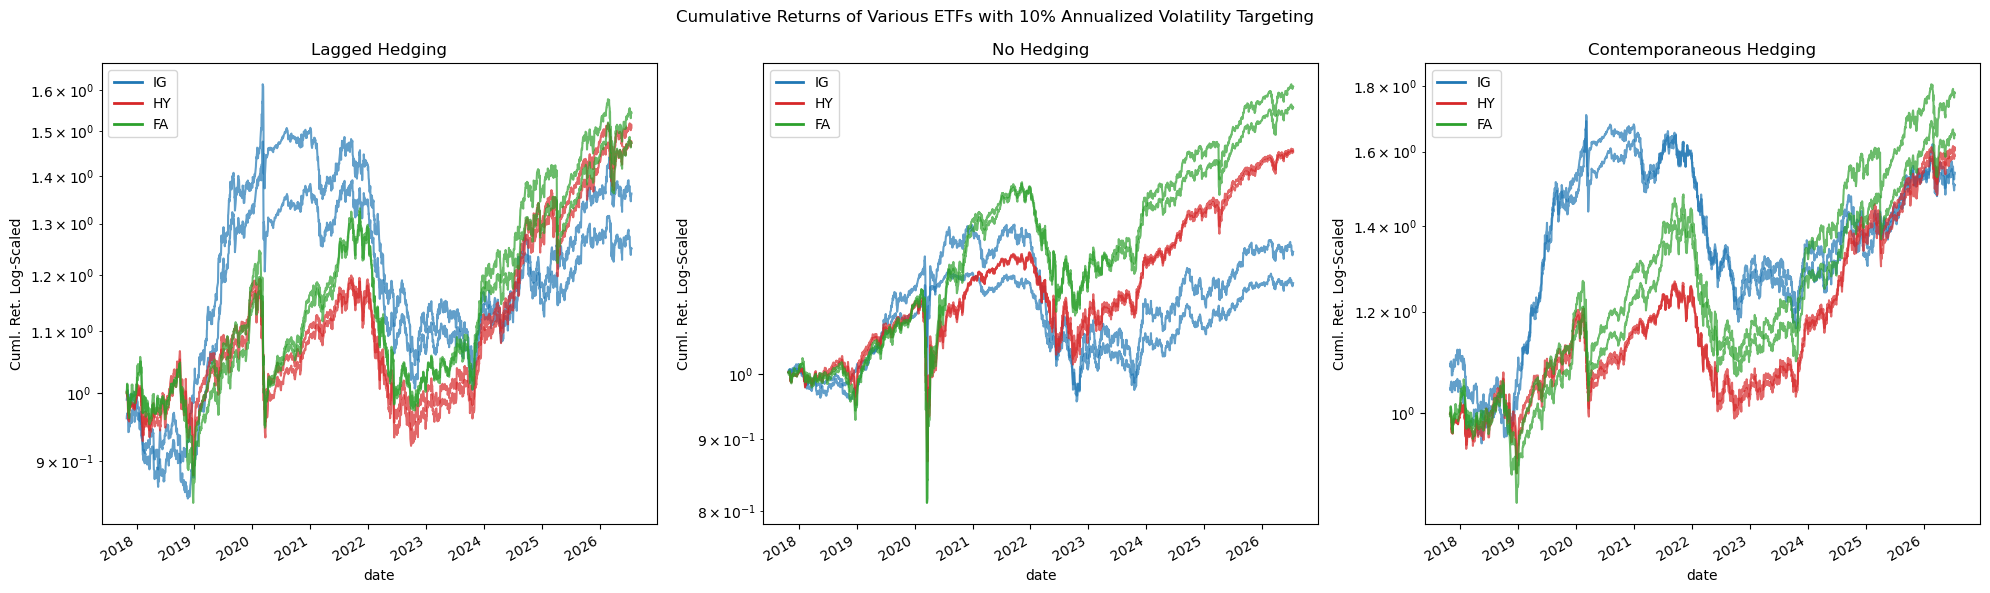

In [53]:
hedges = df_combined.hedging.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(hedges), figsize = (20, 6))

for hedge, ax in zip(hedges, axes.flatten()): 

    df_plot = (df_combined.loc[
        lambda x: x.hedging == hedge].
        rename(columns = {"ticker": ""}).
        pivot(index = "date", columns = "", values = "rtn")    .
        dropna().
        apply(lambda x: np.cumprod(1 + x)))

    for key in etf_groups.keys():

        (df_plot[
            etf_groups[key]].
            plot(
                logy   = True,
                ax     = ax,
                color  = etf_color[key],
                alpha  = 0.7,
                legend = False,
                ylabel = "Cuml. Ret. Log-Scaled"))

    legend_handles = [
        Line2D(
            [0], [0],
            color=etf_color[group],
            lw=2,
            label=group
        )
        for group in etf_groups
    ]

    ax.legend(handles=legend_handles)
    ax.set_title(RENAMER[hedge] + " Hedging")

fig.suptitle("Cumulative Returns of Various ETFs with 10% Annualized Volatility Targeting")
plt.tight_layout()
plt.show()

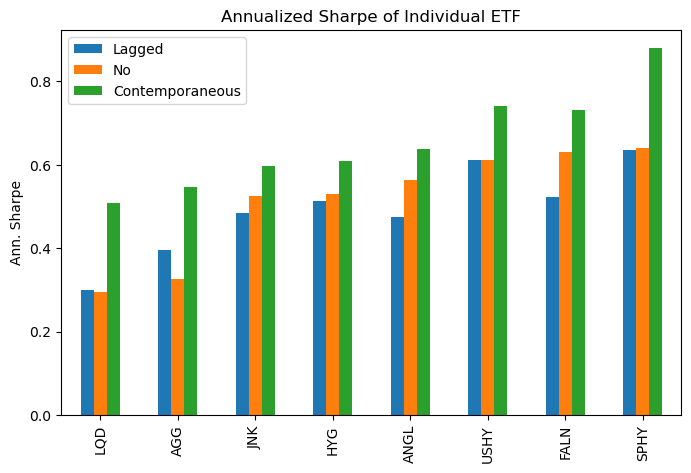

In [55]:
(df_combined.drop(
    columns = ["date"]).
    dropna().
    groupby(["ticker", "hedging"]).
    agg(lambda x: x.mean() / x.std() * np.sqrt(252)).
    reset_index().
    rename(columns = {"hedging": ""}).
    pivot(index = "ticker", columns = "", values = "rtn").
    rename(columns = RENAMER).
    sort_values(["No"]).
    plot(
        kind    = "bar",
        ylabel  = "Ann. Sharpe",
        title   = "Annualized Sharpe of Individual ETF",
        xlabel  = "",
        figsize = (8,5)))

plt.show()

Something to note is that there is a considerable sharpe reduction between contemperanous hedging and lagged hedging which implies that duration risk is quite important

In [56]:
(df_combined.query(
    "hedging != 'none'").
    drop(columns = ["date"]).
    dropna().
    groupby(["ticker", "hedging"]).
    agg(lambda x: x.mean() / x.std() * np.sqrt(252)).
    reset_index().
    rename(columns = {"hedging": ""}).
    pivot(index = "ticker", columns = "", values = "rtn").
    assign(spread = lambda x: x.perf - x.lagged).
    rename(columns = RENAMER).
    sort_values("spread").
    rename(columns = {"spread": "Sharpe Lost"}))

,Lagged,Contemporaneous,Sharpe Lost
ticker,,,
HYG,0.511945,0.608945,0.097000
JNK,0.484691,0.596231,0.111540
USHY,0.612485,0.741315,0.128830
AGG,0.394509,0.547654,0.153146
ANGL,0.475577,0.637780,0.162202
LQD,0.300254,0.507059,0.206805
FALN,0.522770,0.730389,0.207618
SPHY,0.634752,0.879316,0.244564


In [57]:
df_corr = (df_combined.pivot(
    index = ["date", "hedging"], columns = "ticker", values = "rtn").
    reset_index().
    dropna().
    drop(columns = ["date"]).
    groupby("hedging").
    agg("corr")
    [["ANGL", "FALN"]].
    reset_index().
    query("ticker != ['ANGL', 'FALN']").
    rename(columns = {"ticker": "tmp_ticker"}).
    melt(id_vars = ["hedging", "tmp_ticker"]))

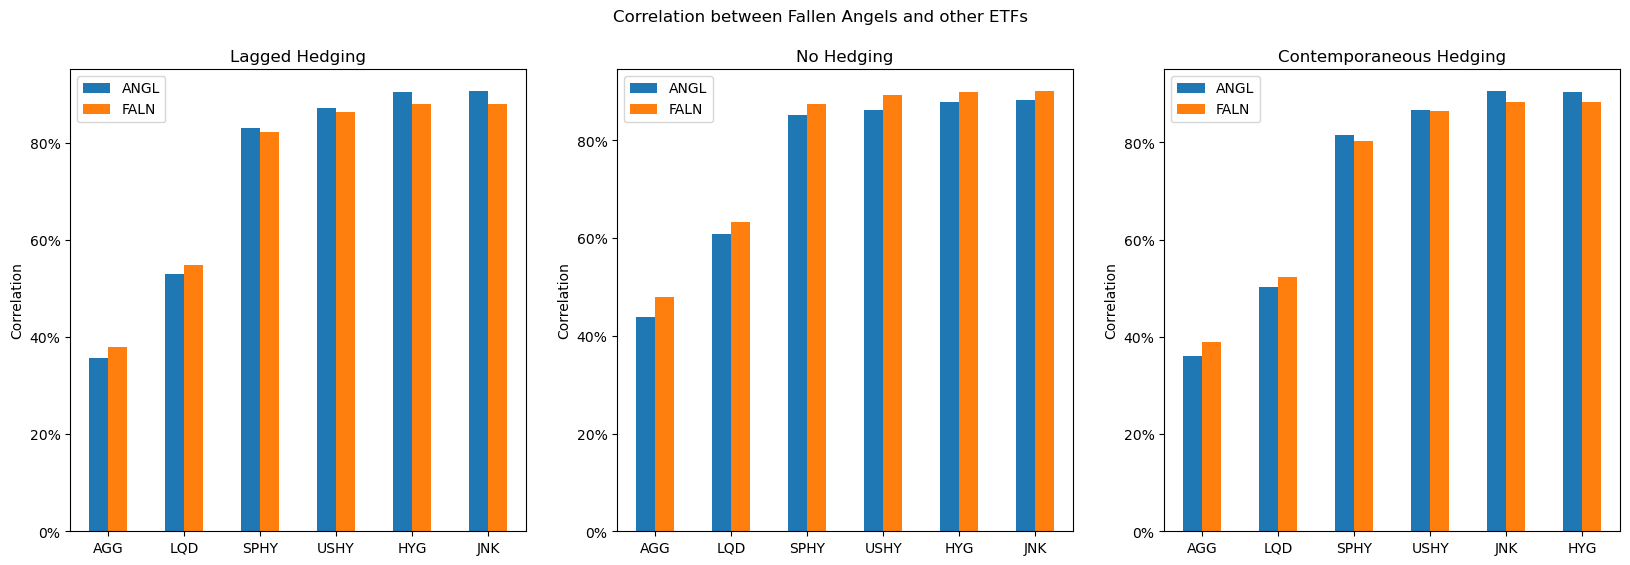

In [58]:
fig, axes = plt.subplots(ncols = len(hedges), figsize = (20,6))
for hedge, ax in zip(hedges, axes.flatten()):  

    (df_corr.query(
        "hedging == @hedge").
        rename(columns = {"ticker": ""}).
        pivot(index = "tmp_ticker", columns = "", values = "value").
        sort_values("FALN").
        plot(
            ax     = ax,
            kind   = "bar",
            rot    = 0,
            xlabel = "",
            ylabel = "Correlation",
            title  = RENAMER[hedge] + " Hedging"))

    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{(y):.0%}"))

fig.suptitle("Correlation between Fallen Angels and other ETFs")
plt.show()

In [59]:
df_spread = (df_combined.pivot(
    index = ["date", "hedging"], columns = "ticker", values = "rtn").
    reset_index().
    melt(id_vars = ["date", "hedging", "ANGL", "FALN"], var_name = "fi_ticker", value_name = "fi_rtn").
    melt(id_vars = ["date", "hedging", "fi_ticker", "fi_rtn"], var_name = "fa_ticker", value_name = "fa_rtn").
    dropna().
    assign(
        spread = lambda x: 0.5 * (x.fa_rtn - x.fi_rtn),
        group_var = lambda x: x.fa_ticker + "-" + x.fi_ticker))

In [60]:
df_none = (df_spread.loc[lambda x: x.hedging == "none"]
    [["date", "hedging", "spread", "group_var", "fi_ticker"]])

df_perf = (df_spread.loc[lambda x: x.hedging == "perf"].
    pivot(index = "date", columns = "group_var", values = "spread").
    apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252)))).
    reset_index().
    melt(id_vars = "date", value_name = "spread").
    assign(
        fi_ticker = lambda x: x.group_var.str.split("-").str[1],
        hedging   = "perf"))

df_lagged = (df_spread.loc[lambda x: x.hedging == "lagged"].
    pivot(index = "date", columns = "group_var", values = "spread").
    apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std().shift() * np.sqrt(252)))).
    reset_index().
    melt(id_vars = "date", value_name = "spread").
    assign(
        fi_ticker = lambda x: x.group_var.str.split("-").str[1],
        hedging   = "lagged"))

df_ls = pd.concat([df_none, df_perf, df_lagged])

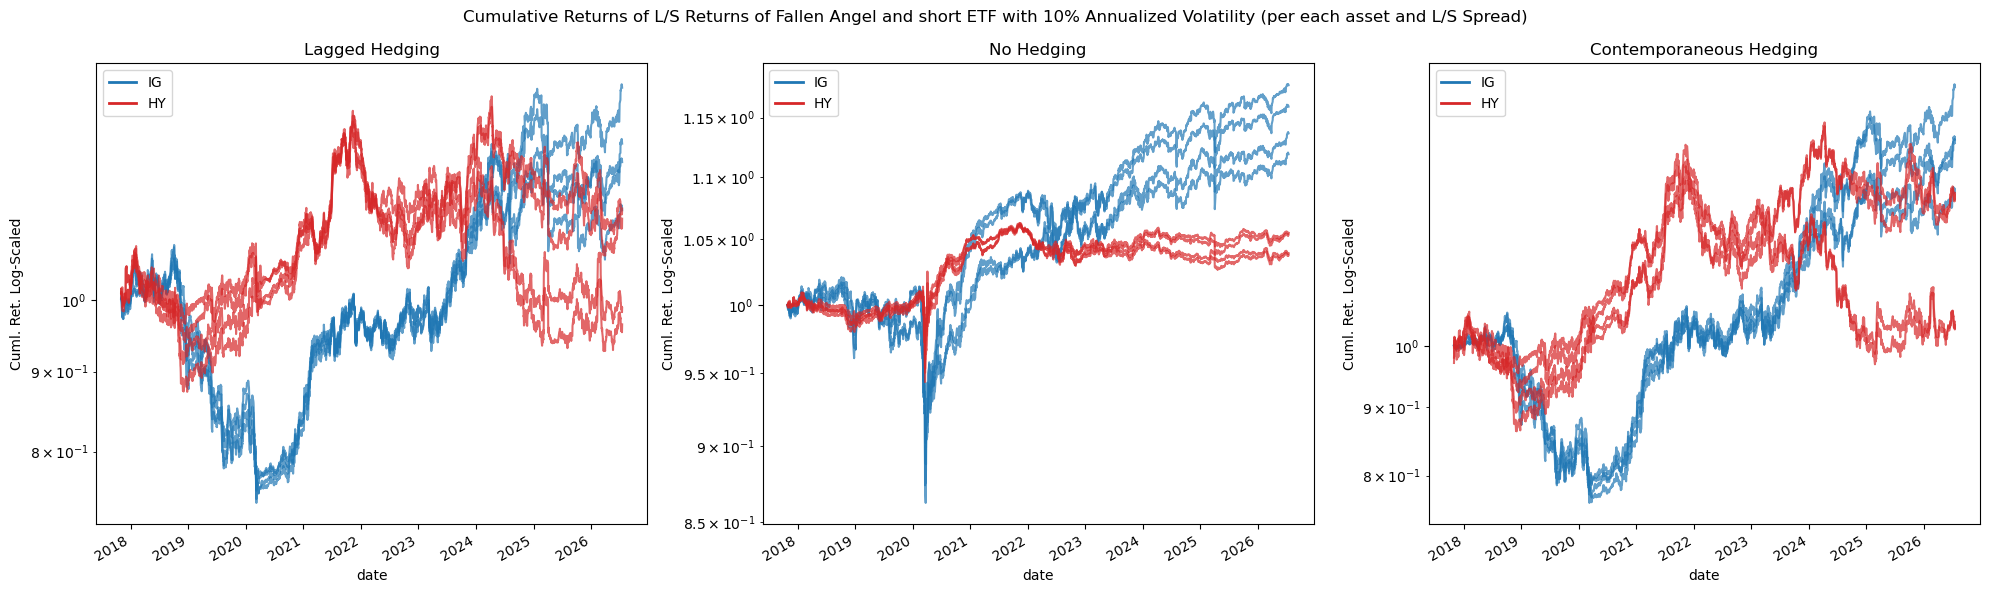

In [61]:
fig, axes = plt.subplots(ncols = len(hedges), figsize = (20,6))
tmp_keys  = ["IG", "HY"]

for hedge, ax in zip(hedges, axes.flatten()): 

    df_tmp = df_ls.loc[lambda x: x.hedging == hedge]
    
    for key in tmp_keys: 

        tickers = etf_groups[key]
        (df_tmp.loc[
            lambda x: x.fi_ticker.isin(tickers)].
            pivot(index = "date", columns = "group_var", values = "spread").
            apply(lambda x: np.cumprod(1 + x)).
            plot(
                logy   = True,
                ax     = ax,
                legend = False,
                color  = etf_color[key],
                alpha  = 0.7,
                ylabel = "Cuml. Ret. Log-Scaled"))

    legend_handles = [
        Line2D(
            [0], [0],
            color=etf_color[group],
            lw=2,
            label=group
        )
        for group in tmp_keys
    ]
    ax.legend(handles=legend_handles)
    ax.set_title(RENAMER[hedge] + " Hedging")

fig.suptitle("Cumulative Returns of L/S Returns of Fallen Angel and short ETF with 10% Annualized Volatility (per each asset and L/S Spread)")
plt.tight_layout()
plt.show()

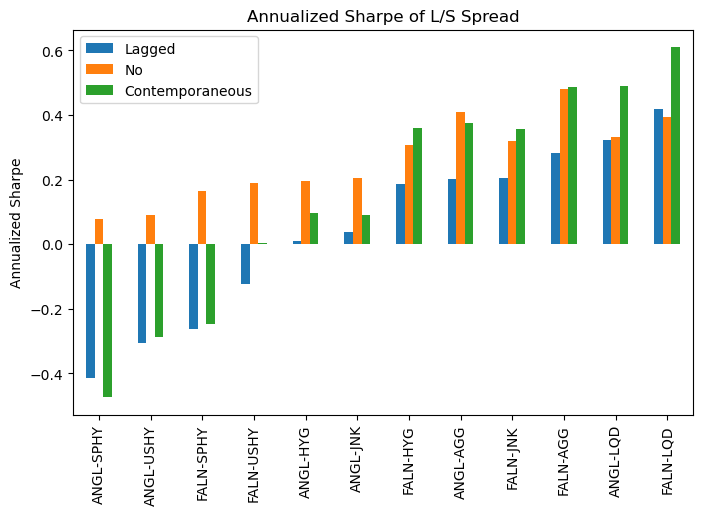

In [62]:
(df_ls[
    ["hedging", "spread", "group_var"]].
    groupby(["hedging", "group_var"]).
    agg(lambda x: x.mean() / x.std() * np.sqrt(252)).
    reset_index().
    rename(columns = {"hedging": ""}).
    pivot(index = "group_var", columns = "", values = "spread").
    sort_values("lagged").
    rename(columns = RENAMER).
    plot(
        figsize = (8,5),
        kind    = "bar",
        ylabel  = "Annualized Sharpe",
        title   = "Annualized Sharpe of L/S Spread",
        xlabel  = ""))

plt.show()

In [63]:
def _get_beta(df: pd.DataFrame, endog: str = "fa_rtn", exog: str =  ["fi_rtn"]) -> pd.DataFrame: 

    model = (sm.OLS(
        endog = df[endog],
        exog  = sm.add_constant(df[exog])).
        fit())

    df_params  = model.params.to_frame(name = "param_val").reset_index()
    df_pvalues = model.pvalues.to_frame(name = "pvalues").reset_index()
    df_tvalues = model.tvalues.to_frame(name = "tvalues").reset_index()

    df_out = (df_params.merge(
        right = df_pvalues, how = "inner", on = ["index"]).
        merge(right = df_tvalues, how = "inner", on = ["index"]))

    return df_out

df_params = (df_spread.assign(
    group_var = lambda x: x.hedging + " " + x.fi_ticker + "~" + x.fa_ticker).
    groupby("group_var").
    apply(_get_beta).
    reset_index().
    drop(columns = ["level_1"]).
    rename(columns = {"index": "variable"}))

In [64]:
display(df_params.assign(
    hedging = lambda x: x.group_var.str.split(" ").str[0],
    model   = lambda x: x.group_var.str.split(" ").str[1]).
    loc[lambda x: x.variable == "fi_rtn"].
    drop(columns = ["group_var", "variable"]).
    melt(id_vars = ["hedging", "model"]).
    rename(columns = {
        "variable": "",
        "hedging" : "Hedging"}).
    replace(RENAMER).
    replace({
        "param_val": "Param Val", 
        "pvalues"  : r"$p$-values",
        "tvalues"  : r"$t$-values"}).
    pivot(index = "model", columns = ["", "Hedging"], values = "value"))

Param Val                               $p$-values                 \
Hedging      Lagged        No Contemporaneous         Lagged             No   
model                                                                         
AGG~ANGL   0.362684  0.747937        0.353903   7.586082e-67  1.732122e-103   
AGG~FALN   0.389346  0.775252        0.378907   6.122157e-76  1.003566e-125   
HYG~ANGL   0.929011  0.991022        0.909736   0.000000e+00   0.000000e+00   
HYG~FALN   0.912164  0.962466        0.882344   0.000000e+00   0.000000e+00   
JNK~ANGL   0.928640  0.995526        0.910440   0.000000e+00   0.000000e+00   
JNK~FALN   0.910672  0.964896        0.881379   0.000000e+00   0.000000e+00   
LQD~ANGL   0.539122  0.646126        0.473632  4.570239e-159  1.847193e-222   
LQD~FALN   0.563867  0.636829        0.491158  1.177022e-172  8.993718e-245   
SPHY~ANGL  0.817613  1.043840        0.817857   0.000000e+00   0.000000e+00   
SPHY~FALN  0.817263  1.017435        0.801126   0.000000e+00   0.000000e+00   
USHY~ANGL  0.889035  1.018700        0.874504   0.000000e+00   0.000000e+00   
USHY~FALN  0.890122  1.002402        0.865347   0.000000e+00   0.000000e+00   

                           $t$-values                             
Hedging   Contemporaneous      Lagged         No Contemporaneous  
model                                                             
AGG~ANGL     1.484923e-68   17.881031  22.809110       18.130824  
AGG~FALN     2.918357e-80   19.184705  25.491111       19.782215  
HYG~ANGL     0.000000e+00   99.633845  85.830704       99.070146  
HYG~FALN     0.000000e+00   86.588425  95.594040       87.931259  
JNK~ANGL     0.000000e+00  100.744275  87.627647       99.712510  
JNK~FALN     0.000000e+00   86.875334  96.933038       87.655118  
LQD~ANGL    4.726217e-140   29.256555  35.914289       27.140327  
LQD~FALN    1.226625e-154   30.727667  38.169807       28.769185  
SPHY~ANGL    0.000000e+00   69.964042  76.402159       65.768921  
SPHY~FALN    0.000000e+00   67.667834  84.790297       63.142584  
USHY~ANGL    0.000000e+00   83.359551  79.557215       81.586303  
USHY~FALN    0.000000e+00   80.399961  93.054317       80.319671

In [65]:
df_combined_params = (df_combined.pivot(
    index = ["date", "hedging"], columns = "ticker", values = "rtn").
    reset_index().
    melt(id_vars = ["date", "hedging", "AGG", "HYG", "JNK", "LQD"]).
    dropna().
    assign(group_var = lambda x: x.hedging + " " + x.ticker).
    groupby("group_var").
    apply(_get_beta, "value", ["AGG", "HYG", "JNK", "LQD"]).
    reset_index().
    drop(columns = ["level_1"]))

In [66]:
(df_combined_params.melt(
    id_vars = ["group_var", "index"]).
    assign(
        hedging = lambda x: x.group_var.str.split(" ").str[0],
        ticker  = lambda x: x.group_var.str.split(" ").str[1]).
    rename(columns = {
        "variable": "",
        "index"   : "Param Name"}).
    replace(RENAMER).
    replace({
        "Contemporaneous": "Perf",
        "param_val"      : "Param Val",
        "pvalues"        : r"$p$-value",
        "tvalues"        : r"$t$-value"}).
    pivot(index = ["ticker", "hedging"], columns = ["", "Param Name"], values = "value"))

Param Val                                         $p$-value  \
Param Name         const       AGG       HYG       JNK       LQD     const   
ticker hedging                                                               
ANGL   Lagged   0.000010 -0.020590  0.298932  0.582342  0.114571  0.858111   
       No       0.000038  0.024547 -0.061851  0.960420  0.147489  0.523789   
       Perf     0.000026  0.041747  0.344377  0.537755  0.036799  0.632203   
FALN   Lagged   0.000035 -0.026303  0.301904  0.537662  0.165194  0.589705   
       No       0.000053  0.152662  0.073401  0.803409  0.081130  0.298092   
       Perf     0.000062  0.060091  0.368983  0.467230  0.058686  0.294777   
SPHY   Lagged   0.000096 -0.124200  0.300219  0.530903  0.215701  0.182914   
       No       0.000049 -0.059436  0.196901  0.622042  0.088605  0.209487   
       Perf     0.000133 -0.056159  0.341550  0.463855  0.154877  0.041652   
USHY   Lagged   0.000063 -0.041780  0.269044  0.664022  0.059434  0.172828   
       No       0.000032 -0.011618  0.200595  0.715327  0.032003  0.188968   
       Perf     0.000068 -0.043754  0.281895  0.641371  0.063692  0.123072   

                                                                        \
Param Name               AGG           HYG           JNK           LQD   
ticker hedging                                                           
ANGL   Lagged   3.399965e-01  1.187663e-06  2.453870e-21  1.490504e-06   
       No       4.453405e-01  5.312134e-01  2.991776e-22  8.899298e-11   
       Perf     4.898053e-02  8.574933e-09  2.169861e-19  9.601465e-02   
FALN   Lagged   2.776887e-01  1.234133e-05  5.120229e-15  6.865458e-10   
       No       3.078845e-08  3.844181e-01  2.035954e-21  2.824765e-05   
       Perf     9.055934e-03  1.322516e-08  4.774892e-13  1.450097e-02   
SPHY   Lagged   3.250430e-06  7.552279e-05  1.907470e-12  2.502914e-13   
       No       4.794992e-03  2.350714e-03  7.994923e-22  2.593518e-09   
       Perf     2.666053e-02  1.715088e-06  6.593347e-11  5.148950e-09   
USHY   Lagged   1.491755e-02  3.883990e-08  2.633430e-41  1.657946e-03   
       No       3.746949e-01  6.469048e-07  2.538679e-67  5.208878e-04   
       Perf     1.041682e-02  4.881547e-09  9.509544e-40  3.522310e-04   

               $t$-value                                           
Param Name         const       AGG       HYG        JNK       LQD  
ticker hedging                                                     
ANGL   Lagged   0.178800 -0.954381  4.871402   9.583359  4.825852  
       No       0.637619  0.763344 -0.626255   9.807324  6.516632  
       Perf     0.478696  1.969861  5.779322   9.089605  1.665208  
FALN   Lagged   0.539343 -1.085797  4.381557   7.880005  6.196859  
       No       1.040782  5.557011  0.869959   9.603335  4.196047  
       Perf     1.047952  2.612271  5.704863   7.275904  2.446561  
SPHY   Lagged   1.332259 -4.666433  3.965749   7.082071  7.364727  
       No       1.255348 -2.823386  3.045496   9.703247  5.980392  
       Perf     2.038186 -2.217954  4.797504   6.562383  5.865862  
USHY   Lagged   1.363620 -2.436307  5.515750  13.747433  3.149444  
       No       1.314048 -0.887895  4.991371  17.951176  3.474962  
       Perf     1.542605 -2.563896  5.874843  13.462853  3.579148

# Analyzing Total Returns Indices

For now we'll use the ICE Fallen Angel index data provided by ICE. There are two other indices proivded by Bloomberg but they are calculate over monthly frequencies which makes it quite difficult to aggregate daily returns of other indices and most of the other indices went through periods of monthly frequency prior to daily. 

In [67]:
good_indices_ = ["LF98TRUU", "H0CF", "LBUSTRUU"]
good_indices  = ["{} Index".format(index) for index in good_indices_]

path = os.path.join(data_path, "RawData", "IndexTotalReturn.parquet")
slice_date = dt.date(year = 1998, month = 10, day = 1)

df_index_rtn = (pd.read_parquet(
    path = path, engine = "pyarrow").
    assign(date = lambda x: pd.to_datetime(x.date).dt.date).
    loc[lambda x: x.security.isin(good_indices)].
    loc[lambda x: x.date >= slice_date].
    assign(security = lambda x: x.security.str.split(" ").str[0]).
    pivot(index = "date", columns = "security", values = "rtn").
    dropna())

In [68]:
df_perf = (df_index_rtn.apply(
    lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252)))).
    reset_index().
    melt(id_vars = "date", value_name = "rtn").
    assign(hedging = "perf").
    dropna())

df_lagged = (df_index_rtn.apply(
    lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std().shift() * np.sqrt(252)))).
    reset_index().
    melt(id_vars = "date", value_name = "rtn").
    assign(hedging = "lagged").
    dropna())

df_raw_rtn = (df_index_rtn.reset_index().melt(
    id_vars = "date", value_name = "rtn").
    assign(hedging = "raw"))

In [69]:
df_combined = pd.concat([df_perf, df_lagged, df_raw_rtn])

RENAMER = {
    "lagged"  : "Lagged",
    "perf"    : "Contemporaneous",
    "raw"     : "No",
    "LF98TRUU": "BBG HY", 
    "H0CF"    : "ICE FA",
    "LBUSTRUU": "BBG IG"} 

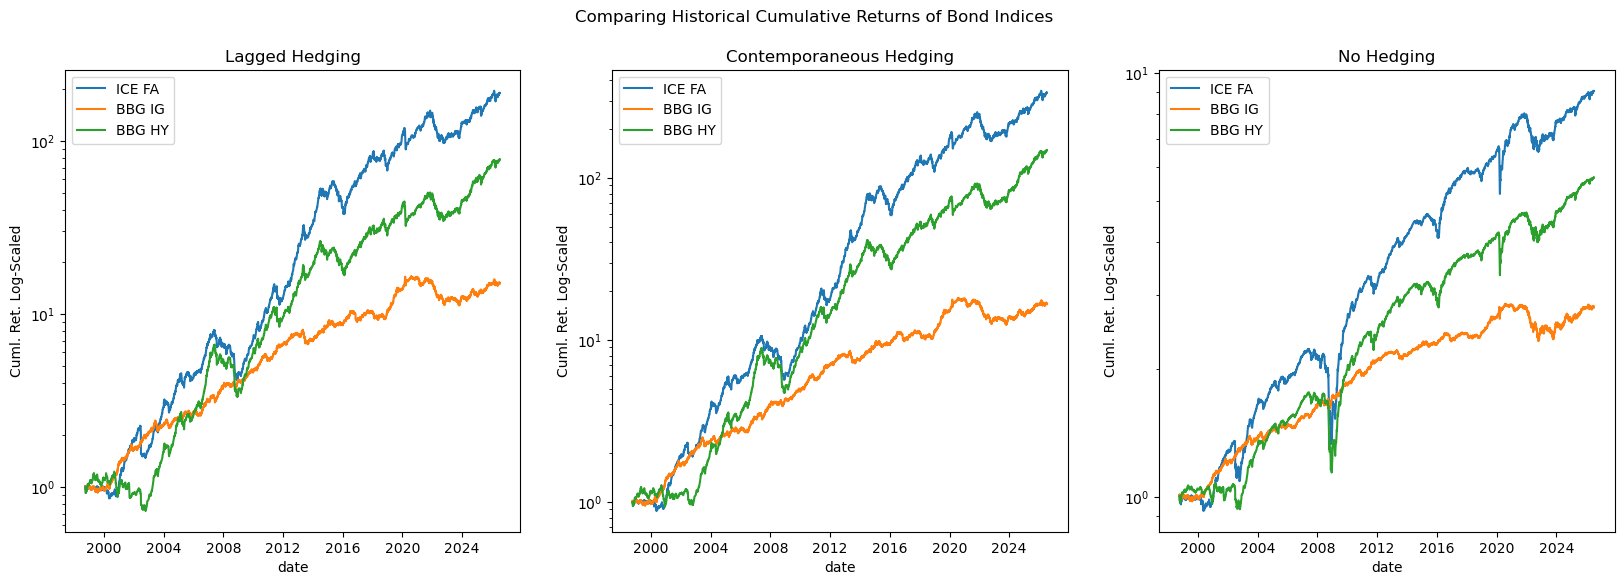

In [70]:
group_vars = df_combined.hedging.drop_duplicates().sort_values().to_list()
fig, axes  = plt.subplots(ncols = len(group_vars), figsize = (20,6))

for group_var, ax in zip(group_vars, axes.flatten()): 

    (df_combined.loc[
        lambda x: x.hedging == group_var].
        rename(columns = {"security": ""}).
        pivot(index = "date", columns = "", values = "rtn").
        apply(lambda x: np.cumprod(1 + x)).
        rename(columns = RENAMER).
        plot(
            ax     = ax,
            ylabel = "Cuml. Ret. Log-Scaled", 
            title  = RENAMER[group_var] + " Hedging",
            logy   = True))

fig.suptitle("Comparing Historical Cumulative Returns of Bond Indices")
plt.show()

Now calculate the sharpe of the returns controlling for the volatility targeting

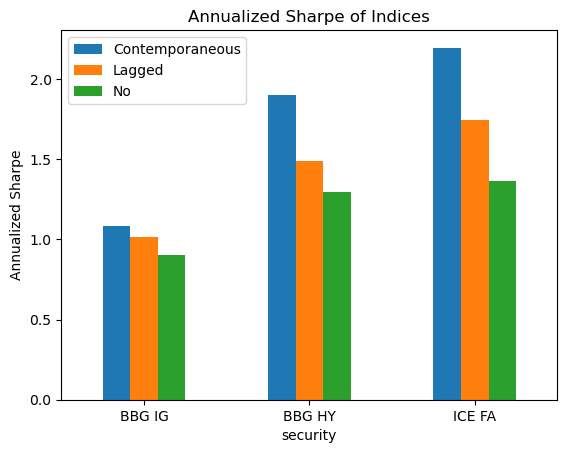

In [71]:
df_long_sharpe = (df_combined.drop(
    columns = ["date"]).
    groupby(["security", "hedging"]).
    agg(lambda x: x.mean() / x.std() * np.sqrt(252)))
    
(df_long_sharpe.
    reset_index().
    rename(columns = {"hedging": ""}).
    replace(RENAMER).
    pivot(index = "security", columns = "", values = "rtn").
    sort_values("No").
    plot(
        kind   = "bar", 
        rot    = 0,
        ylabel = "Annualized Sharpe",
        title  = "Annualized Sharpe of Indices"))

plt.show()

The sharpe lost from going contemporaneously hedged to lagged hedging can be quite expensive in sharpe terms specifically with Fallen Angels

In [72]:
(df_long_sharpe.reset_index().loc[
    lambda x: x.hedging != "raw"].
    replace(RENAMER).
    rename(columns = {"hedging": ""}).
    pivot(index = "security", columns = "", values = "rtn").
    assign(spread = lambda x: x.Contemporaneous - x.Lagged).
    apply(lambda x: np.round(x,3)))

,Contemporaneous,Lagged,spread
security,,,
BBG HY,1.899,1.487,0.412
BBG IG,1.082,1.017,0.065
ICE FA,2.195,1.743,0.452


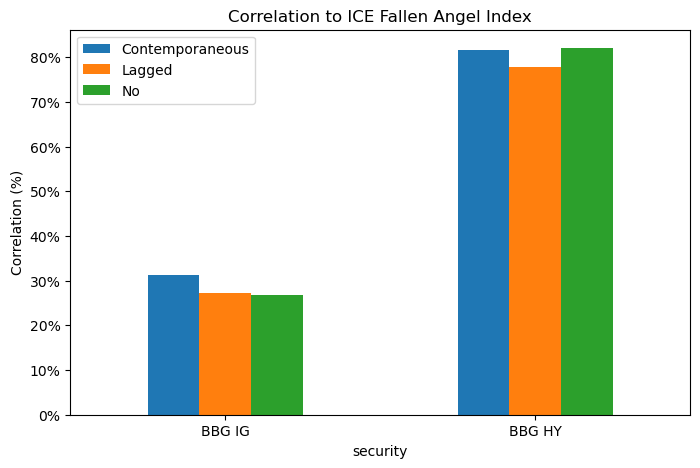

In [73]:
fig, axes = plt.subplots(figsize = (8,5))

(df_combined.pivot(
    index = ["date", "hedging"], columns = "security", values = "rtn").
    reset_index().
    melt(id_vars = ["date", "hedging", "H0CF"]).
    drop(columns = ["date"]).
    groupby(["hedging", "security"]).
    agg("corr").
    query("value != 1").
    reset_index().
    replace(RENAMER).
    rename(columns = {
        "hedging": ""}).
    pivot(index = "security", columns = "", values = "value").
    sort_values("No").
    plot(
        kind   = "bar",
        rot    = 0,
        ax     = axes,
        ylabel = "Correlation (%)",
        title  = "Correlation to ICE Fallen Angel Index"))

axes.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{(y):.0%}"))
plt.show()

In [74]:
df_spread = (df_combined.pivot(
    index = ["date", "hedging"], columns = "security", values = "rtn").
    reset_index().
    melt(id_vars = ["date", "hedging", "H0CF"]).
    assign(spread = lambda x: 0.5 * (x.H0CF - x.value)))

In [75]:
df_raw = (df_spread.loc[
    lambda x: x.hedging == "raw"]
    [["date", "security", "spread", "hedging"]])

df_perf = (df_spread.loc[
    lambda x: x.hedging == "perf"].
    pivot(index = "date", columns = "security", values = "spread").
    apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252)))).
    reset_index().
    melt(id_vars = "date", value_name = "spread").
    assign(hedging = "perf"))

df_lag = (df_spread.loc[
    lambda x: x.hedging == "lagged"].
    pivot(index = "date", columns = "security", values = "spread").
    apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252)))).
    reset_index().
    melt(id_vars = "date", value_name = "spread").
    assign(hedging = "lagged"))

df_spread_combined = pd.concat([df_raw, df_perf, df_lag])

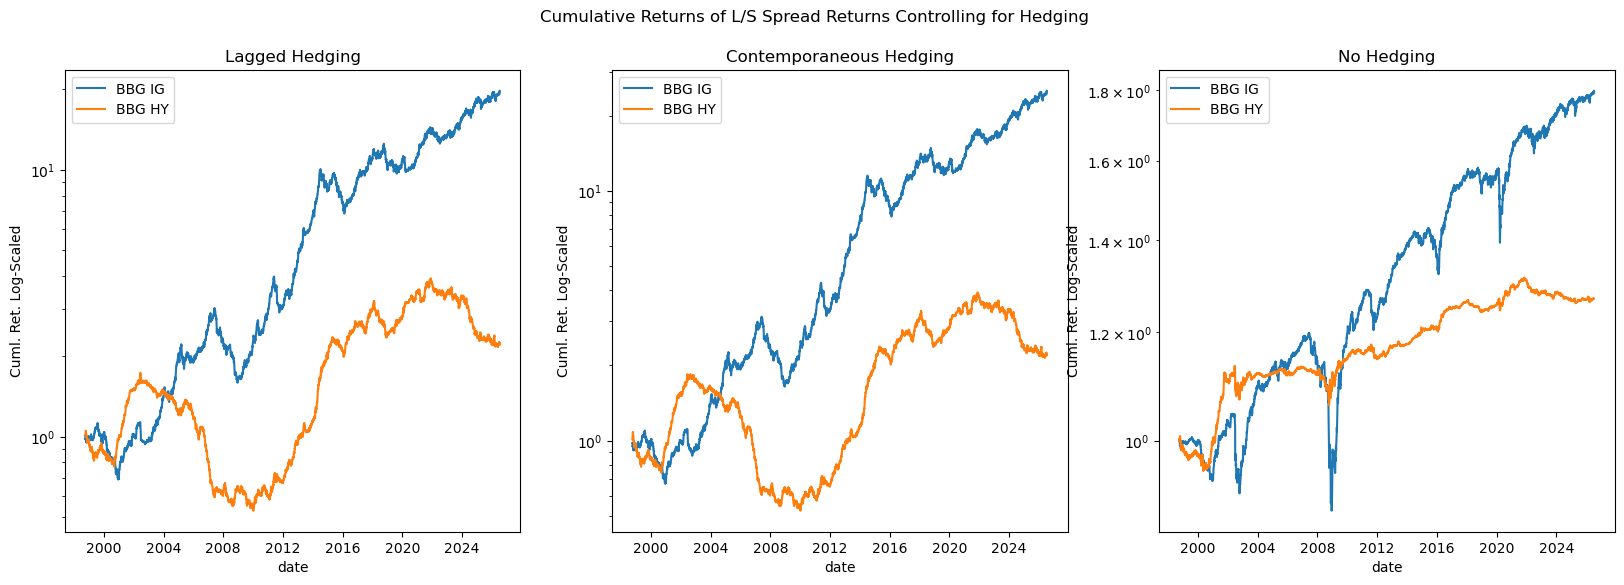

In [76]:
hedgings  = df_spread_combined.hedging.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = 3, figsize = (20,6))

for hedge, ax in zip(hedgings, axes.flatten()): 

    (df_spread_combined.loc[
        lambda x: x.hedging == hedge].
        rename(columns = {"security": ""}).
        pivot(index = "date", columns = "", values = "spread").
        rename(columns = RENAMER).
        apply(lambda x: np.cumprod(1 + x)).
        plot(
            ax     = ax,
            logy   = True,
            ylabel = "Cuml. Ret. Log-Scaled",
            title  = RENAMER[hedge] + " Hedging"))

fig.suptitle("Cumulative Returns of L/S Spread Returns Controlling for Hedging")
plt.show()

In [77]:
(df_spread_combined.drop(
    columns = ["date"]).
    groupby(["security", "hedging"]).
    agg(lambda x: x.mean() / x.std() * np.sqrt(252)).
    reset_index().
    rename(columns = {"hedging": ""}).
    replace(RENAMER).
    pivot(index = "security", columns = "", values = "spread").
    apply(lambda x: np.round(x,3)))

,Contemporaneous,Lagged,No
security,,,
BBG HY,0.337,0.343,0.515
BBG IG,1.215,1.141,0.688


# Analyze the Relationship between Index and ETF Returns

In [78]:
def compare_returns(
    df_index_rtn: pd.DataFrame, 
    index_ticker: str, 
    etf_path    : str,
    etf_ticker  : str) -> pd.DataFrame:

    df_index     = df_index_rtn[[index_ticker]]
    df_index_vol = df_index.apply(lambda x: x.ewm(span = 100, adjust = False).std() * np.sqrt(252))
    
    df_etf_rtn_wider = (pd
        .read_parquet(path = etf_path, engine = "pyarrow")
        .loc[lambda x: x.Price.isin(["Adj Close", "Close"])]
        .loc[lambda x: x.ticker == etf_ticker]
        .assign(date = lambda x: pd.to_datetime(x.date).dt.date)
        .pivot(index = "date", columns = "Price", values = "value")
        .rename(columns = {
            "Adj Close": "AdjPX",
            "Close"    : "PX"})
        .pct_change())
    
    df_etf_rtn_longer = (df_etf_rtn_wider
        .reset_index()
        .melt(id_vars = "date", var_name = "rtn_type", value_name = "rtn"))
    
    df_etf_prep = (df_etf_rtn_wider
        .apply(lambda x: x.ewm(span = 100, adjust = False).std() * np.sqrt(252))
        .reset_index()
        .melt(id_vars = "date", var_name = "rtn_type", value_name = "vol")
        .dropna()
        .merge(right = df_index_vol, how = "inner", on = ["date"])
        .assign(weight = lambda x: x[index_ticker] / x.vol)
        .merge(right = df_etf_rtn_longer, how = "inner", on = ["date", "rtn_type"])
        .assign(vol_rtn = lambda x: x.weight * x.rtn)
        [["date", "rtn_type", "vol_rtn", "rtn"]]
        .rename(columns = {
            "vol_rtn": "perf",
            "rtn"    : "none"})
        .melt(id_vars = ["date", "rtn_type"], var_name = "vol_target", value_name = "value")
        .merge(right = df_index, how = "inner", on = ["date"]))

    return df_etf_prep

In [79]:
def _get_tracking_error(df: pd.DataFrame, benchmark_name: str) -> pd.DataFrame: 

    active_rtn = df["value"] - df[benchmark_name]

    return pd.Series({
        "tracking_error"   : active_rtn.std() * np.sqrt(252),
        "active_return"    : active_rtn.mean() * 252,
        "information_ratio": (
            active_rtn.mean() / active_rtn.std()
        ) * np.sqrt(252),
        "correlation": df["value"].corr(df[benchmark_name]),
        "rmse": np.sqrt(np.mean(active_rtn ** 2))
    })

def get_tracking_error(df: pd.DataFrame, benchmark_name: str) -> pd.DataFrame: 

    df_out = (df
        .set_index("date")
        .replace(RENAMER)
        .rename(columns = {
            "vol_target": "Vol. Target",
            "rtn_type"  : "Rtn. Type"})
        .groupby(["Rtn. Type", "Vol. Target"])
        .apply(_get_tracking_error, benchmark_name)
        .rename(columns = {
            "tracking_error"   : "Tracking Error",
            "active_return"    : "Active Return",
            "information_ratio": "Information Ratio",
            "correlation"      : "Correlation",
            "rmse"             : "RMSE"}))

    return df_out

In [80]:
(
    compare_returns(df_index_rtn, "H0CF", etf_path, "ANGL")
    .pipe(get_tracking_error, "H0CF"))

Tracking Error  Active Return  Information Ratio  \
Rtn. Type Vol. Target                                                         
AdjPX     Contemporaneous        0.036668      -0.031153          -0.849587   
          none                   0.071767       0.002052           0.028597   
PX        Contemporaneous        0.037264      -0.061210          -1.642604   
          none                   0.072985      -0.054550          -0.747411   

                           Correlation      RMSE  
Rtn. Type Vol. Target                             
AdjPX     Contemporaneous     0.714215  0.002313  
          none                0.637120  0.004520  
PX        Contemporaneous     0.705483  0.002360  
          none                0.630190  0.004602

In [81]:
(
    compare_returns(df_index_rtn, "LBUSTRUU", etf_path, "AGG")
    .pipe(get_tracking_error, "LBUSTRUU"))

Tracking Error  Active Return  Information Ratio  \
Rtn. Type Vol. Target                                                         
AdjPX     Contemporaneous        0.019702      -0.006757          -0.342979   
          none                   0.029543      -0.003672          -0.124282   
PX        Contemporaneous        0.021159      -0.036010          -1.701851   
          none                   0.031119      -0.035940          -1.154937   

                           Correlation      RMSE  
Rtn. Type Vol. Target                             
AdjPX     Contemporaneous     0.892000  0.001241  
          none                0.816281  0.001861  
PX        Contemporaneous     0.875410  0.001340  
          none                0.802164  0.001965